### Library

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats.mstats import winsorize
from sklearn.preprocessing import LabelEncoder

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_rows", 60)

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "font.family": "sans-serif",
})
PALETTE = {"good": "#2196F3", "bad": "#E53935", "neutral": "#78909C"}

print("✓ Thư viện đã sẵn sàng")

✓ Thư viện đã sẵn sàng


### Raw data checking

In [4]:
# Call raw data
df_raw = pd.read_csv('Data/cs-training.csv', index_col=0)

In [6]:
# Rename Column
RENAME_MAP = {
    "SeriousDlqin2yrs":                        "target",
    "RevolvingUtilizationOfUnsecuredLines":     "revolving_util",
    "age":                                      "age",
    "NumberOfTime30-59DaysPastDueNotWorse":     "past_due_30_59",
    "DebtRatio":                                "debt_ratio",
    "MonthlyIncome":                            "monthly_income",
    "NumberOfOpenCreditLinesAndLoans":          "open_credit_lines",
    "NumberOfTimes90DaysLate":                  "late_90_days",
    "NumberRealEstateLoansOrLines":             "real_estate_loans",
    "NumberOfTime60-89DaysPastDueNotWorse":     "past_due_60_89",
    "NumberOfDependents":                       "dependents",
}
df_raw = df_raw.rename(columns=RENAME_MAP)

print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print("─" * 50)
df_raw.head()

Shape: 150,000 rows × 11 columns
──────────────────────────────────────────────────


,target,revolving_util,age,past_due_30_59,debt_ratio,monthly_income,open_credit_lines,late_90_days,real_estate_loans,past_due_60_89,dependents
1,1,0.7661,45,2,0.8030,"9,120.0000",13,0,6,0,2.0000
2,0,0.9572,40,0,0.1219,"2,600.0000",4,0,0,0,1.0000
3,0,0.6582,38,1,0.0851,"3,042.0000",2,1,0,0,0.0000
4,0,0.2338,30,0,0.0360,"3,300.0000",5,0,0,0,0.0000
5,0,0.9072,49,1,0.0249,"63,588.0000",7,0,1,0,0.0000


In [8]:
#Overview
print("── Kiểu dữ liệu ──")
print(df_raw.dtypes.to_string())
print()

── Kiểu dữ liệu ──
target                 int64
revolving_util       float64
age                    int64
past_due_30_59         int64
debt_ratio           float64
monthly_income       float64
open_credit_lines      int64
late_90_days           int64
real_estate_loans      int64
past_due_60_89         int64
dependents           float64



In [10]:
#Descriptive Statistics
df_raw.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
target,"150,000.0000",0.0668,0.2497,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000
revolving_util,"150,000.0000",6.0484,249.7554,0.0000,0.0000,0.0000,0.0299,0.1542,0.5590,1.0000,1.0930,"50,708.0000"
age,"150,000.0000",52.2952,14.7719,0.0000,24.0000,29.0000,41.0000,52.0000,63.0000,78.0000,87.0000,109.0000
past_due_30_59,"150,000.0000",0.4210,4.1928,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,4.0000,98.0000
debt_ratio,"150,000.0000",353.0051,"2,037.8185",0.0000,0.0000,0.0043,0.1751,0.3665,0.8683,"2,449.0000","4,979.0400","329,664.0000"
monthly_income,"120,269.0000","6,670.2212","14,384.6742",0.0000,0.0000,"1,300.0000","3,400.0000","5,400.0000","8,249.0000","14,587.6000","25,000.0000","3,008,750.0000"
open_credit_lines,"150,000.0000",8.4528,5.1460,0.0000,0.0000,2.0000,5.0000,8.0000,11.0000,18.0000,24.0000,58.0000
late_90_days,"150,000.0000",0.2660,4.1693,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,98.0000
real_estate_loans,"150,000.0000",1.0182,1.1298,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,3.0000,4.0000,54.0000
past_due_60_89,"150,000.0000",0.2404,4.1552,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,98.0000


### Target analysis
##### Biến target = 1 nghĩa là khách hàng bị quá hạn trên 90 ngày trong vòng 2 năm tới — đây là định nghĩa "default" của dataset này.

In [13]:
# Target Distribution
target_counts = df_raw["target"].value_counts()
target_pct    = df_raw["target"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Quantity":   target_counts,
    "Ratio (%)":  target_pct.round(2),
    "Label":       {0: "Good (không default)", 1: "Bad (default)"},
})
print(target_summary.to_string())

   Quantity  Ratio (%)                 Label
0    139974    93.3200  Good (không default)
1     10026     6.6800         Bad (default)


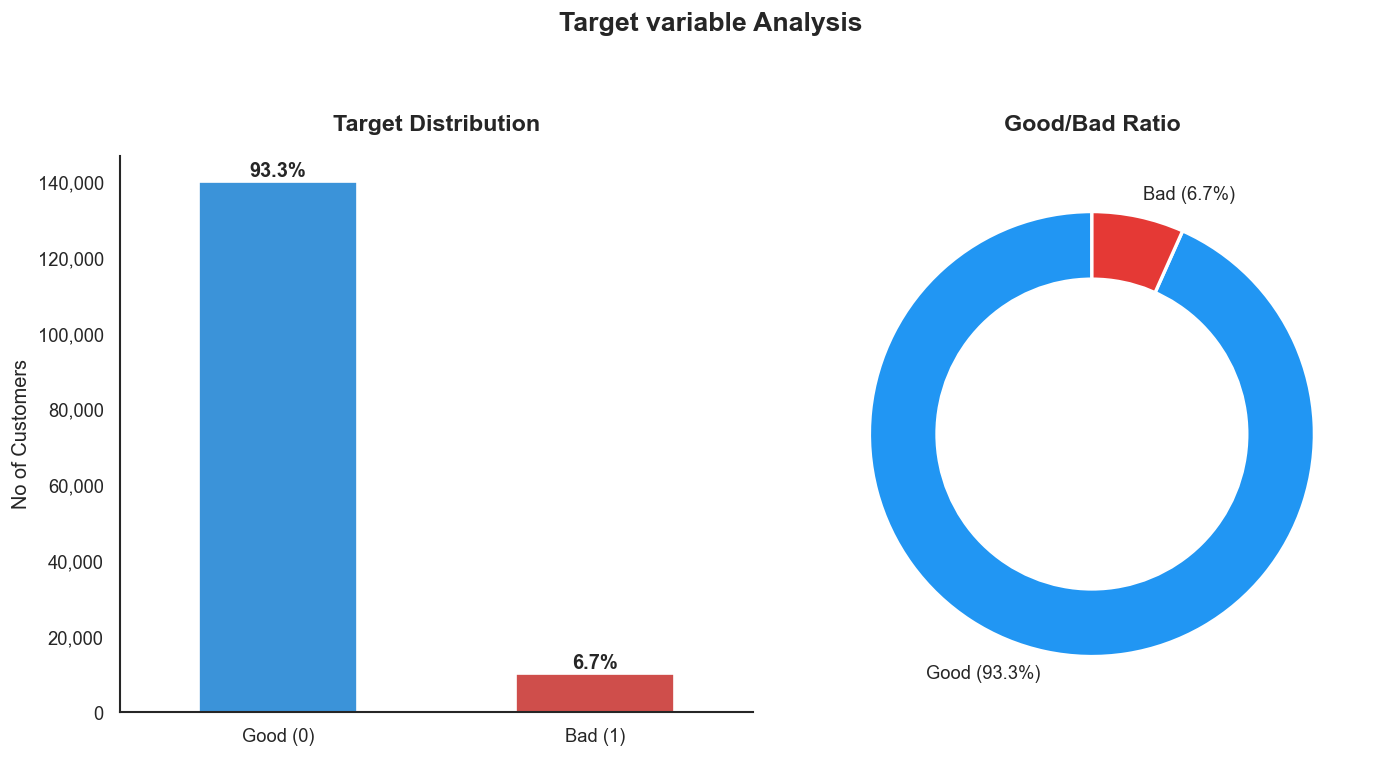


⚠️  Comment: IMBALANCED dataset — Bad ratio around 6.7%.
   → Khi train model sẽ dùng class_weight='balanced' để bù lại.


In [15]:
sns.set_theme(style="white")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

#Bar chart
ax0 = sns.barplot(
    x=["Good (0)", "Bad (1)"], 
    y=target_counts.values, 
    ax=axes[0],
    palette=[PALETTE["good"], PALETTE["bad"]],
    hue=["Good (0)", "Bad (1)"], # Để tránh warning về palette
    legend=False,
    edgecolor="white",
    width=0.5
)

#Column
for i, p in enumerate(ax0.patches):
    percentage = target_pct.values[i]
    ax0.annotate(
        f"{percentage:.1f}%", 
        (p.get_x() + p.get_width() / 2., p.get_height() + 500), 
        ha='center', va='bottom', 
        fontsize=12, fontweight='bold'
    )

ax0.set_title("Target Distribution", fontsize=14, pad=15)
ax0.set_ylabel("No of Customers")
ax0.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

sns.despine(ax=ax0)

#Pie chart
labels_with_pct = [f"Good ({target_pct.values[0]:.1f}%)", 
                   f"Bad ({target_pct.values[1]:.1f}%)"]
axes[1].pie(
    target_counts.values,
    labels=labels_with_pct,
    colors=[PALETTE["good"], PALETTE["bad"]],
    startangle=90,
    pctdistance=0.85, # Khoảng cách của text nếu bạn muốn để % bên trong
    wedgeprops={"edgecolor": "white", "linewidth": 2, "antialiased": True},
    textprops={"fontsize": 11}
)

centre_circle = plt.Circle((0,0), 0.70, fc='white')
axes[1].add_artist(centre_circle)

axes[1].set_title("Good/Bad Ratio", fontsize=14, pad=15)

plt.suptitle("Target variable Analysis", fontsize=16, fontweight="bold", y=1.05)
plt.tight_layout()

plt.savefig("01_target_distribution.png", bbox_inches="tight", dpi=300)
plt.show()

print()
print("⚠️  Comment: IMBALANCED dataset — Bad ratio around 6.7%.")
print("   → Khi train model sẽ dùng class_weight='balanced' để bù lại.")

### Missing value analysis

In [17]:
# ── Bảng tổng hợp missing ───────────────────────────────────────────────────
def missing_summary(df: pd.DataFrame) -> pd.DataFrame:
    """
    Trả về DataFrame tổng hợp missing values, sắp xếp theo tỷ lệ giảm dần.
    Bao gồm dtype và gợi ý xử lý.
    """
    total   = df.isnull().sum()
    percent = total / len(df) * 100
    dtype   = df.dtypes

    summary = pd.DataFrame({
        "Missing count": total,
        "Missing %":     percent.round(2),
        "Dtype":         dtype,
    }).sort_values("Missing %", ascending=False)

    # Gợi ý xử lý tự động
    def suggest(row):
        if row["Missing %"] == 0:
            return "—"
        if row["Missing %"] > 30:
            return "Cân nhắc loại bỏ hoặc flag riêng"
        if row["Dtype"] in ["float64", "int64"]:
            return "Điền median (robust với outliers)"
        return "Điền mode"

    summary["Gợi ý xử lý"] = summary.apply(suggest, axis=1)
    return summary[summary["Missing count"] > 0]

miss_df = missing_summary(df_raw)
print(f"Số cột có missing: {len(miss_df)}")
print()
print(miss_df.to_string())

Số cột có missing: 2

                Missing count  Missing %    Dtype                        Gợi ý xử lý
monthly_income          29731    19.8200  float64  Điền median (robust với outliers)
dependents               3924     2.6200  float64  Điền median (robust với outliers)


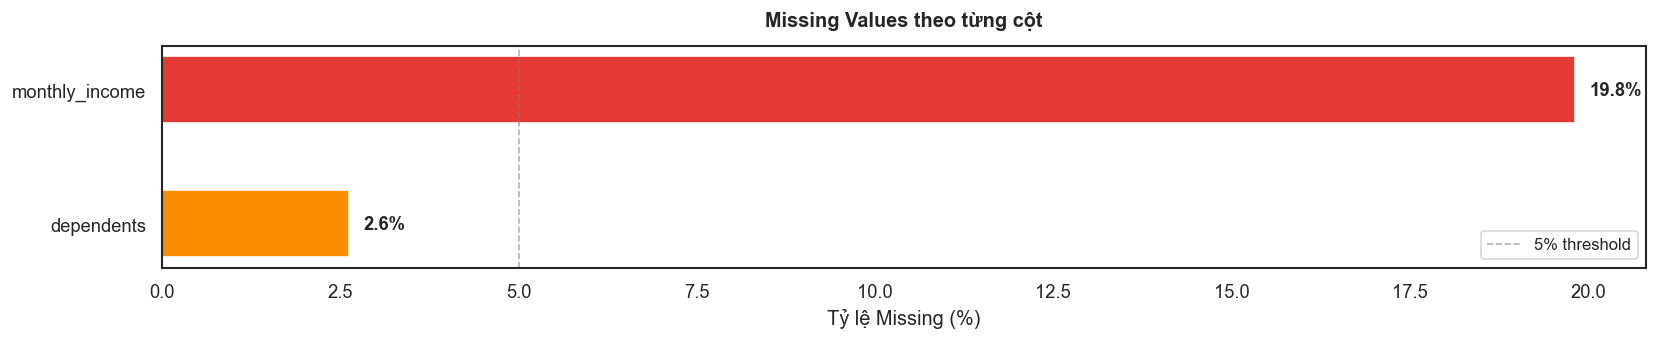

In [18]:
# ── Visualize missing values ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 3))

miss_plot = miss_df[miss_df["Missing %"] > 0].sort_values("Missing %")
bars = ax.barh(
    miss_plot.index,
    miss_plot["Missing %"],
    color=["#E53935" if v > 10 else "#FB8C00" for v in miss_plot["Missing %"]],
    height=0.5,
    edgecolor="white",
)
for bar, val in zip(bars, miss_plot["Missing %"]):
    ax.text(val + 0.2, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=11, fontweight="bold")

ax.axvline(5, color="gray", linestyle="--", linewidth=1, alpha=0.6, label="5% threshold")
ax.set_xlabel("Tỷ lệ Missing (%)")
ax.set_title("Missing Values theo từng cột")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("02_missing_values.png", bbox_inches="tight")
plt.show()


In [21]:
# ── Kiểm tra xem missing có liên quan đến target không ──────────────────────
# Nếu missing tập trung ở nhóm Bad → đây là thông tin có giá trị (MAR/MNAR)

for col in ["monthly_income", "dependents"]:
    miss_flag = df_raw[col].isnull()
    bad_rate_missing  = df_raw.loc[miss_flag,  "target"].mean() * 100
    bad_rate_present  = df_raw.loc[~miss_flag, "target"].mean() * 100
    print(f"[{col}]")
    print(f"  Bad rate khi MISSING  : {bad_rate_missing:.2f}%")
    print(f"  Bad rate khi CÓ GIÁ TRỊ: {bad_rate_present:.2f}%")
    diff = bad_rate_missing - bad_rate_present
    if abs(diff) > 1:
        print(f"  ⚠️  Chênh lệch {diff:+.2f}% → Missing có tương quan với target (MAR/MNAR)")
        print(f"     → Nên tạo thêm cột flag: {col}_is_missing")
    else:
        print(f"  ✓  Chênh lệch nhỏ → Missing ngẫu nhiên (MCAR), điền median là đủ")
    print()


[monthly_income]
  Bad rate khi MISSING  : 5.61%
  Bad rate khi CÓ GIÁ TRỊ: 6.95%
  ⚠️  Chênh lệch -1.33% → Missing có tương quan với target (MAR/MNAR)
     → Nên tạo thêm cột flag: monthly_income_is_missing

[dependents]
  Bad rate khi MISSING  : 4.56%
  Bad rate khi CÓ GIÁ TRỊ: 6.74%
  ⚠️  Chênh lệch -2.18% → Missing có tương quan với target (MAR/MNAR)
     → Nên tạo thêm cột flag: dependents_is_missing



### Outlier analysis
Dùng hai phương pháp: **IQR** (phát hiện outlier dựa trên tứ phân vị) và **percentile** để hiểu mức độ nghiêm trọng trước khi xử lý.

In [25]:
# ── Hàm phân tích outlier ────────────────────────────────────────────────────
def outlier_report(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    """
    Báo cáo outlier theo phương pháp IQR cho danh sách cột số.
    Trả về: số lượng, tỷ lệ outlier, giá trị min/max, và ngưỡng fence.
    """
    rows = []
    for col in cols:
        s   = df[col].dropna()
        q1  = s.quantile(0.25)
        q3  = s.quantile(0.75)
        iqr = q3 - q1
        lo  = q1 - 1.5 * iqr
        hi  = q3 + 1.5 * iqr
        n_out = ((s < lo) | (s > hi)).sum()
        rows.append({
            "Cột":           col,
            "Min thực tế":   round(s.min(), 2),
            "Max thực tế":   round(s.max(), 2),
            "Fence dưới":    round(lo, 2),
            "Fence trên":    round(hi, 2),
            "Số outlier":    n_out,
            "Tỷ lệ (%)":     round(n_out / len(s) * 100, 2),
        })
    return pd.DataFrame(rows).set_index("Cột").sort_values("Tỷ lệ (%)", ascending=False)

NUM_COLS = [c for c in df_raw.columns if c != "target"]
outlier_df = outlier_report(df_raw, NUM_COLS)
print(outlier_df.to_string())


                   Min thực tế    Max thực tế  Fence dưới  Fence trên  Số outlier  Tỷ lệ (%)
Cột                                                                                         
debt_ratio              0.0000   329,664.0000     -0.8600      1.9100       31311    20.8700
past_due_30_59          0.0000        98.0000      0.0000      0.0000       23982    15.9900
dependents              0.0000        20.0000     -1.5000      2.5000       13336     9.1300
late_90_days            0.0000        98.0000      0.0000      0.0000        8338     5.5600
past_due_60_89          0.0000        98.0000      0.0000      0.0000        7604     5.0700
monthly_income          0.0000 3,008,750.0000 -3,873.5000 15,522.5000        4879     4.0600
open_credit_lines       0.0000        58.0000     -4.0000     20.0000        3980     2.6500
real_estate_loans       0.0000        54.0000     -3.0000      5.0000         793     0.5300
revolving_util          0.0000    50,708.0000     -0.7600      1.3500 

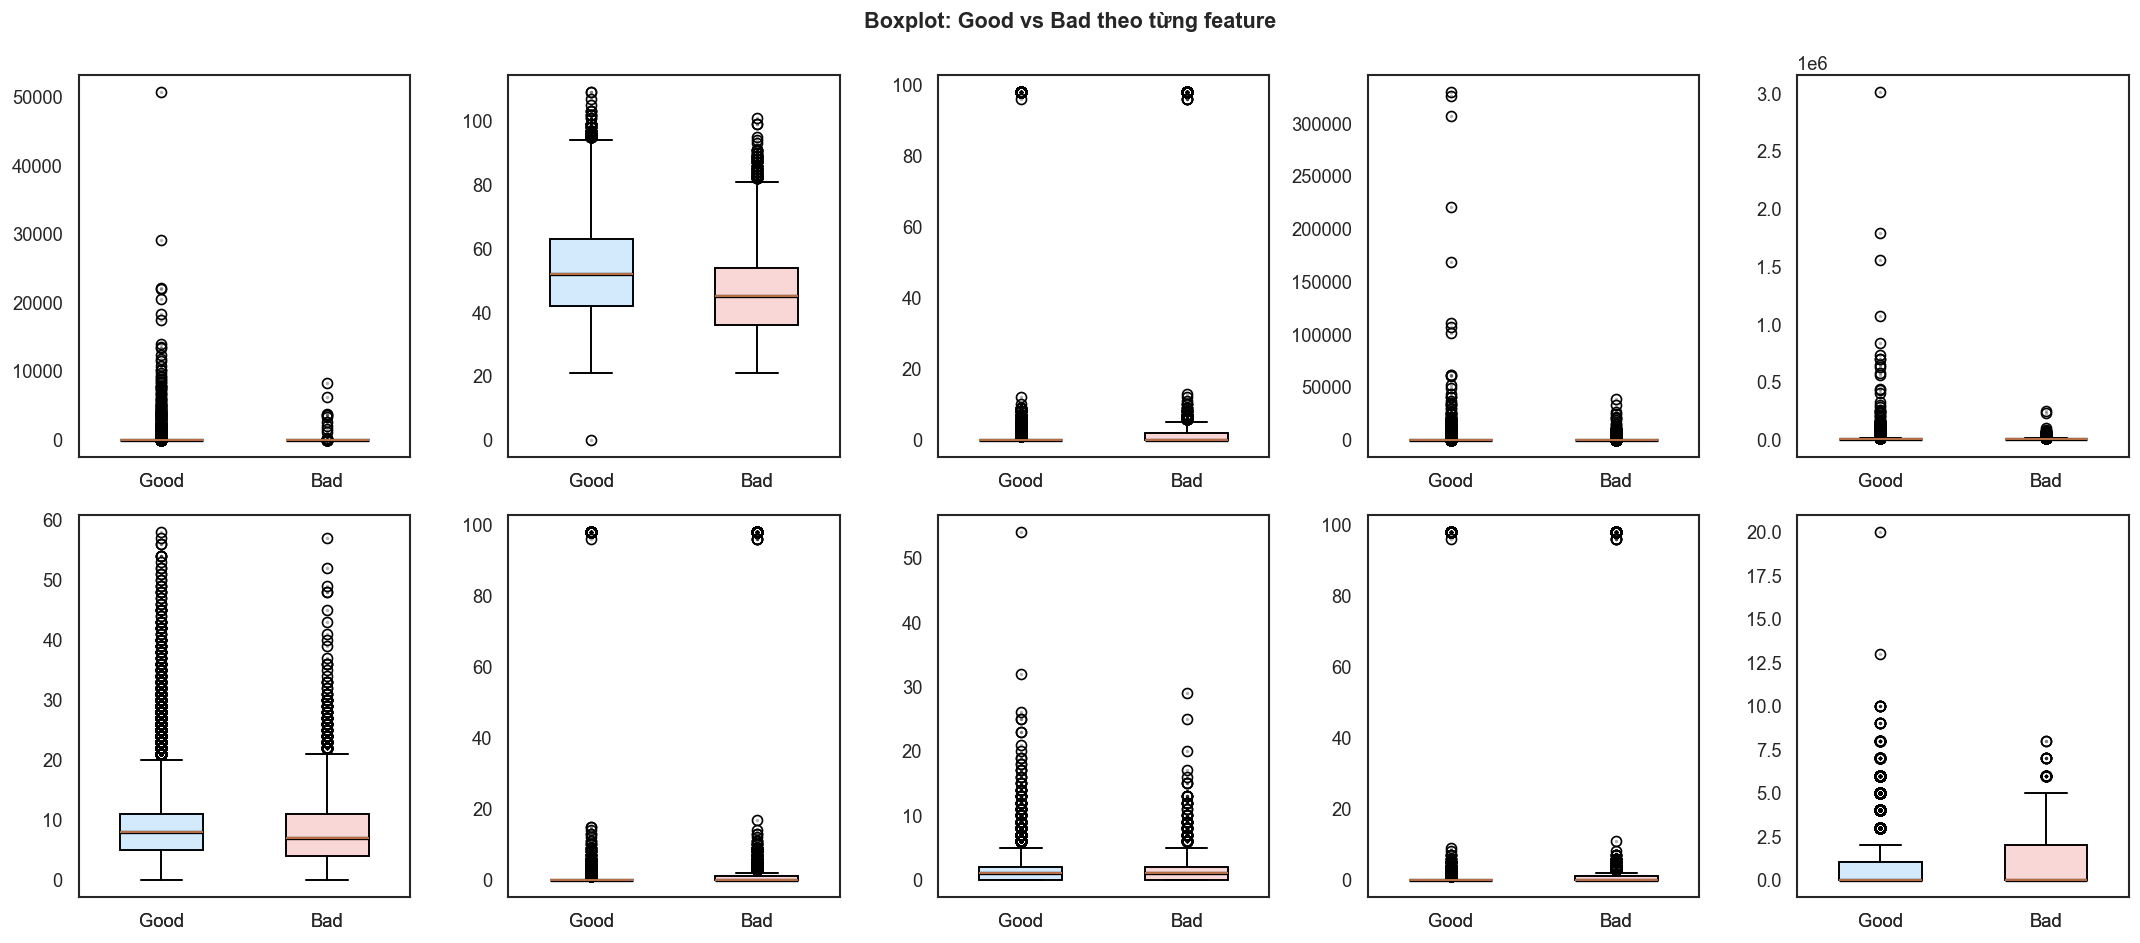

In [27]:
# ── Boxplot toàn bộ features 
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    good = df_raw.loc[df_raw["target"] == 0, col].dropna()
    bad  = df_raw.loc[df_raw["target"] == 1, col].dropna()
    axes[i].boxplot(
        [good, bad],
        labels=["Good", "Bad"],
        patch_artist=True,
        boxprops=dict(facecolor="none"),
        medianprops=dict(color="black", linewidth=2),
        flierprops=dict(marker=".", markersize=2, alpha=0.3),
        widths=0.5,
    )
    # Tô màu
    bp = axes[i].boxplot(
    [good, bad],
    labels=["Good", "Bad"],
    patch_artist=True,   # <-- this makes boxes into Patch objects
    widths=0.5,
)

# Tô màu
    bp["boxes"][0].set_facecolor(PALETTE["good"] + "33")
    bp["boxes"][1].set_facecolor(PALETTE["bad"]  + "33")

# Tắt axis thừa nếu có
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Boxplot: Good vs Bad theo từng feature", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("03_boxplot_features.png", bbox_inches="tight")
plt.show()

### Process Missing Value 
Chiến lược:
- `monthly_income`: tạo cột flag `monthly_income_missing` trước, rồi điền median theo nhóm target
- `dependents`: điền 0 (không có người phụ thuộc là giá trị hợp lý nhất khi missing)

In [29]:
# ── Làm việc trên bản copy để giữ nguyên raw data ───────────────────────────
df = df_raw.copy()

# ── 6.1: Tạo flag cho monthly_income trước khi điền ─────────────────────────
df["monthly_income_missing"] = df["monthly_income"].isnull().astype(int)
print(f"Flag 'monthly_income_missing' created: {df['monthly_income_missing'].sum():,} records flagged")

# ── 6.2: Điền monthly_income bằng median (không dùng mean vì bị ảnh hưởng bởi outlier) ──
median_income = df["monthly_income"].median()
df["monthly_income"] = df["monthly_income"].fillna(median_income)
print(f"monthly_income: điền median = {median_income:,.0f}")

# ── 6.3: Điền dependents = 0 ────────────────────────────────────────────────
df["dependents"] = df["dependents"].fillna(0).astype(int)
print(f"dependents: điền 0 cho {df_raw['dependents'].isnull().sum():,} records")

# ── Kiểm tra: không còn missing ─────────────────────────────────────────────
remaining_missing = df.isnull().sum().sum()
print(f"\n✓ Tổng missing còn lại: {remaining_missing}")
assert remaining_missing == 0, "Vẫn còn missing values — kiểm tra lại!"

Flag 'monthly_income_missing' created: 29,731 records flagged
monthly_income: điền median = 5,400
dependents: điền 0 cho 3,924 records

✓ Tổng missing còn lại: 0


### Xử lý Outliers — Winsorization

**Winsorization** là phương pháp cap giá trị tại ngưỡng percentile thay vì xóa hàng.  
Ưu điểm: giữ nguyên số lượng records, không bóp méo phân phối, chuẩn trong credit scoring.

| Cột có outlier nghiêm trọng | Ngưỡng xử lý |
|---|---|
| `revolving_util` | cap tại 99th percentile (giá trị > 1 là lỗi data) |
| `debt_ratio` | cap tại 99th percentile |
| `monthly_income` | cap tại 1st–99th percentile |
| `past_due_*`, `late_90_days` | cap tại 99th percentile |


In [31]:
# ── Hàm winsorize có logging ─────────────────────────────────────────────────
def winsorize_col(df: pd.DataFrame, col: str,
                  lower: float = 0.0, upper: float = 0.01) -> pd.DataFrame:
    """
    Cap giá trị của cột `col` tại ngưỡng percentile [lower, 1-upper].
    
    Parameters
    ----------
    lower : float — phần trăm bị cap từ phía dưới (0.01 = 1st pct)
    upper : float — phần trăm bị cap từ phía trên (0.01 = 99th pct)
    """
    lo_val = df[col].quantile(lower)    if lower > 0 else -np.inf
    hi_val = df[col].quantile(1-upper)  if upper > 0 else  np.inf

    n_affected = ((df[col] < lo_val) | (df[col] > hi_val)).sum()
    df[col] = df[col].clip(lower=lo_val, upper=hi_val)

    print(f"  {col:35s}  cap [{lo_val:>10.2f}, {hi_val:>12.2f}]  → {n_affected:,} records capped")
    return df


print("Winsorization log:")
print("─" * 80)

# Cột chỉ cap trên (lower = 0)
UPPER_ONLY = [
    "revolving_util", "debt_ratio",
    "past_due_30_59", "past_due_60_89", "late_90_days",
    "open_credit_lines", "real_estate_loans", "dependents",
]
for col in UPPER_ONLY:
    df = winsorize_col(df, col, lower=0.0, upper=0.01)

# monthly_income: cap cả hai phía
df = winsorize_col(df, "monthly_income", lower=0.01, upper=0.01)

# age: giá trị hợp lý là 18–95, xử lý cứng
n_age = ((df["age"] < 18) | (df["age"] > 95)).sum()
df["age"] = df["age"].clip(18, 95)
print(f"  {'age':35s}  clip [18, 95]  → {n_age:,} records capped")

print("─" * 80)
print("✓ Winsorization hoàn tất")

Winsorization log:
────────────────────────────────────────────────────────────────────────────────
  revolving_util                       cap [      -inf,         1.09]  → 1,500 records capped
  debt_ratio                           cap [      -inf,      4979.04]  → 1,500 records capped
  past_due_30_59                       cap [      -inf,         4.00]  → 850 records capped
  past_due_60_89                       cap [      -inf,         2.00]  → 755 records capped
  late_90_days                         cap [      -inf,         3.00]  → 873 records capped
  open_credit_lines                    cap [      -inf,        24.00]  → 1,476 records capped
  real_estate_loans                    cap [      -inf,         4.00]  → 1,482 records capped
  dependents                           cap [      -inf,         4.00]  → 991 records capped
  monthly_income                       cap [      0.00,     23000.00]  → 1,499 records capped
  age                                  clip [18, 95]  → 64 rec

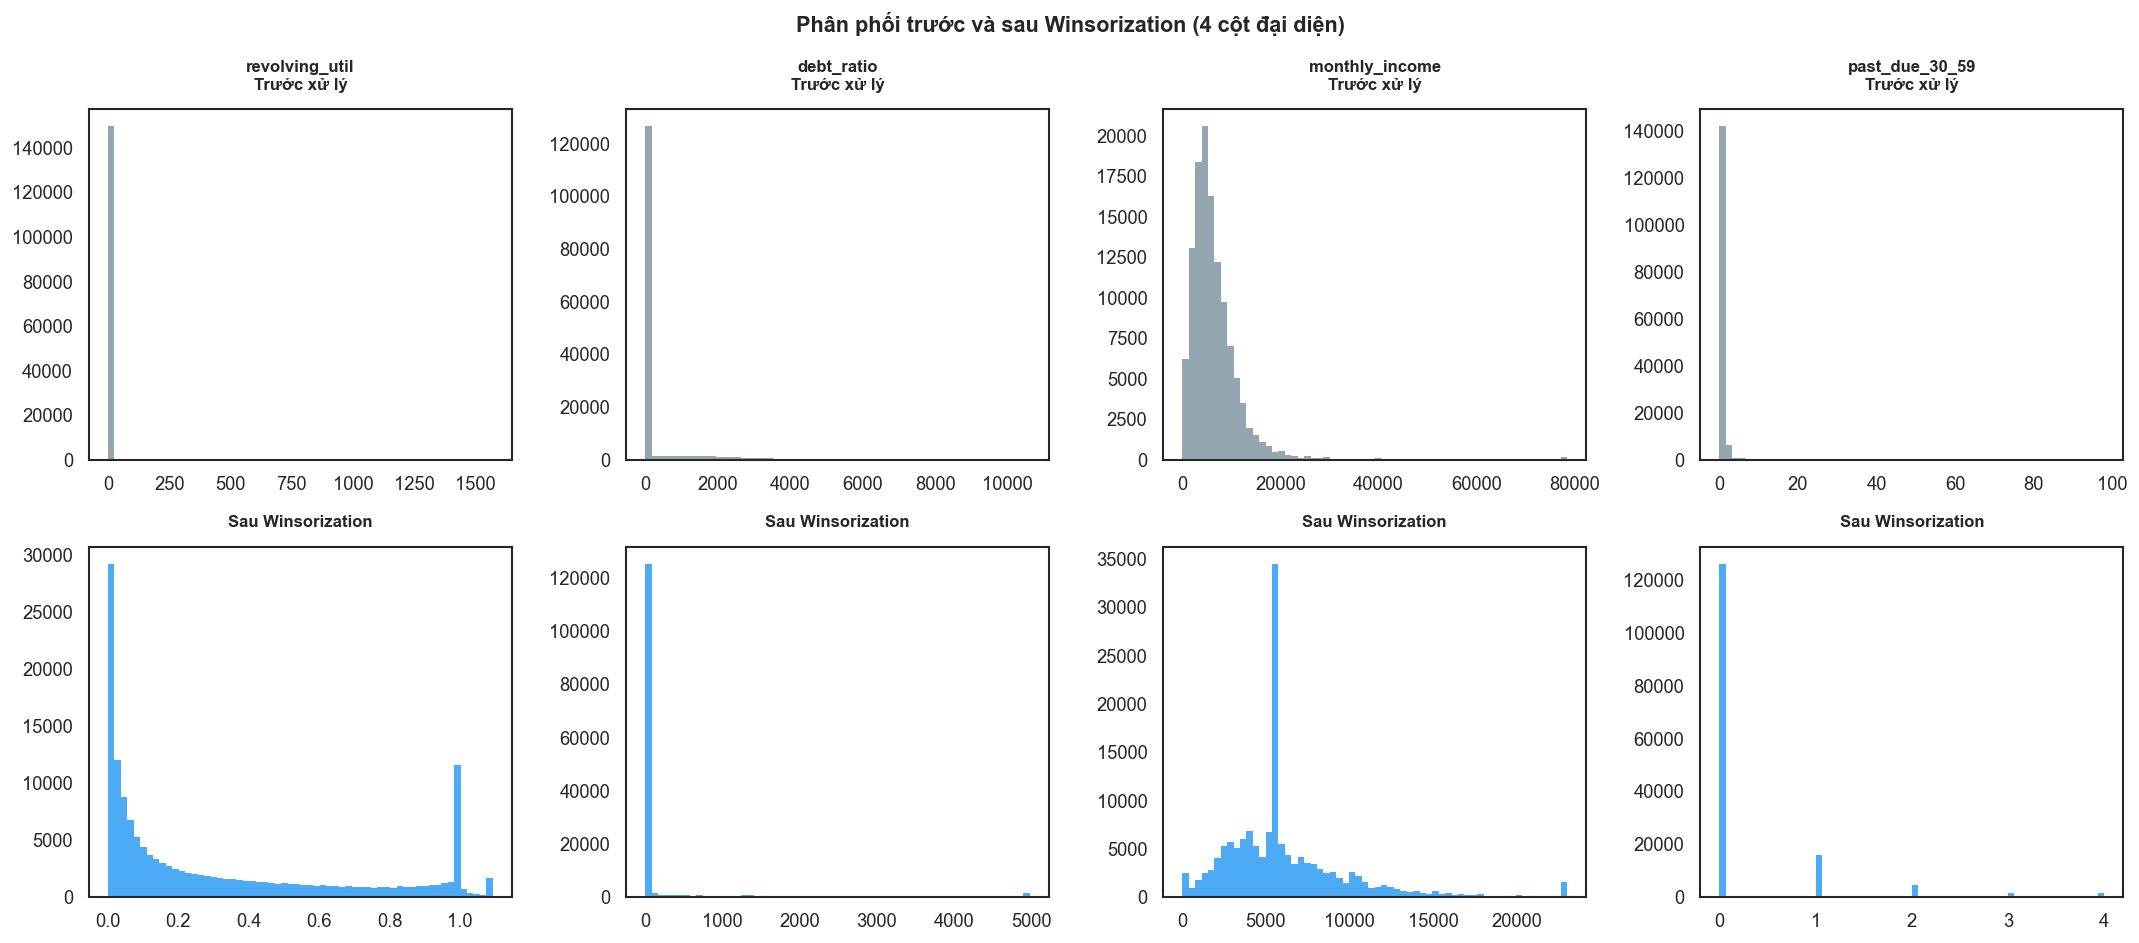

In [34]:
# ── So sánh phân phối trước / sau winsorization ──────────────────────────────
COMPARE_COLS = ["revolving_util", "debt_ratio", "monthly_income", "past_due_30_59"]

fig, axes = plt.subplots(2, len(COMPARE_COLS), figsize=(18, 8))

for i, col in enumerate(COMPARE_COLS):
    # Trước winsorize (từ df_raw, sau khi đã điền missing)
    before = df_raw[col].dropna().clip(
        df_raw[col].quantile(0.001), df_raw[col].quantile(0.999)
    )
    after = df[col]

    # Histogram trước
    axes[0, i].hist(before, bins=60, color=PALETTE["neutral"], edgecolor="none", alpha=0.8)
    axes[0, i].set_title(f"{col}\nTrước xử lý", fontsize=10)

    # Histogram sau
    axes[1, i].hist(after, bins=60, color=PALETTE["good"], edgecolor="none", alpha=0.8)
    axes[1, i].set_title(f"Sau Winsorization", fontsize=10)

plt.suptitle("Phân phối trước và sau Winsorization (4 cột đại diện)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("04_winsorization_comparison.png", bbox_inches="tight")
plt.show()

### Analyzing feature distribution according to Target
Bước này giúp hiểu trực quan feature nào có **khả năng phân tách Good/Bad** cao — cơ sở để kỳ vọng IV cao ở bước WOE.

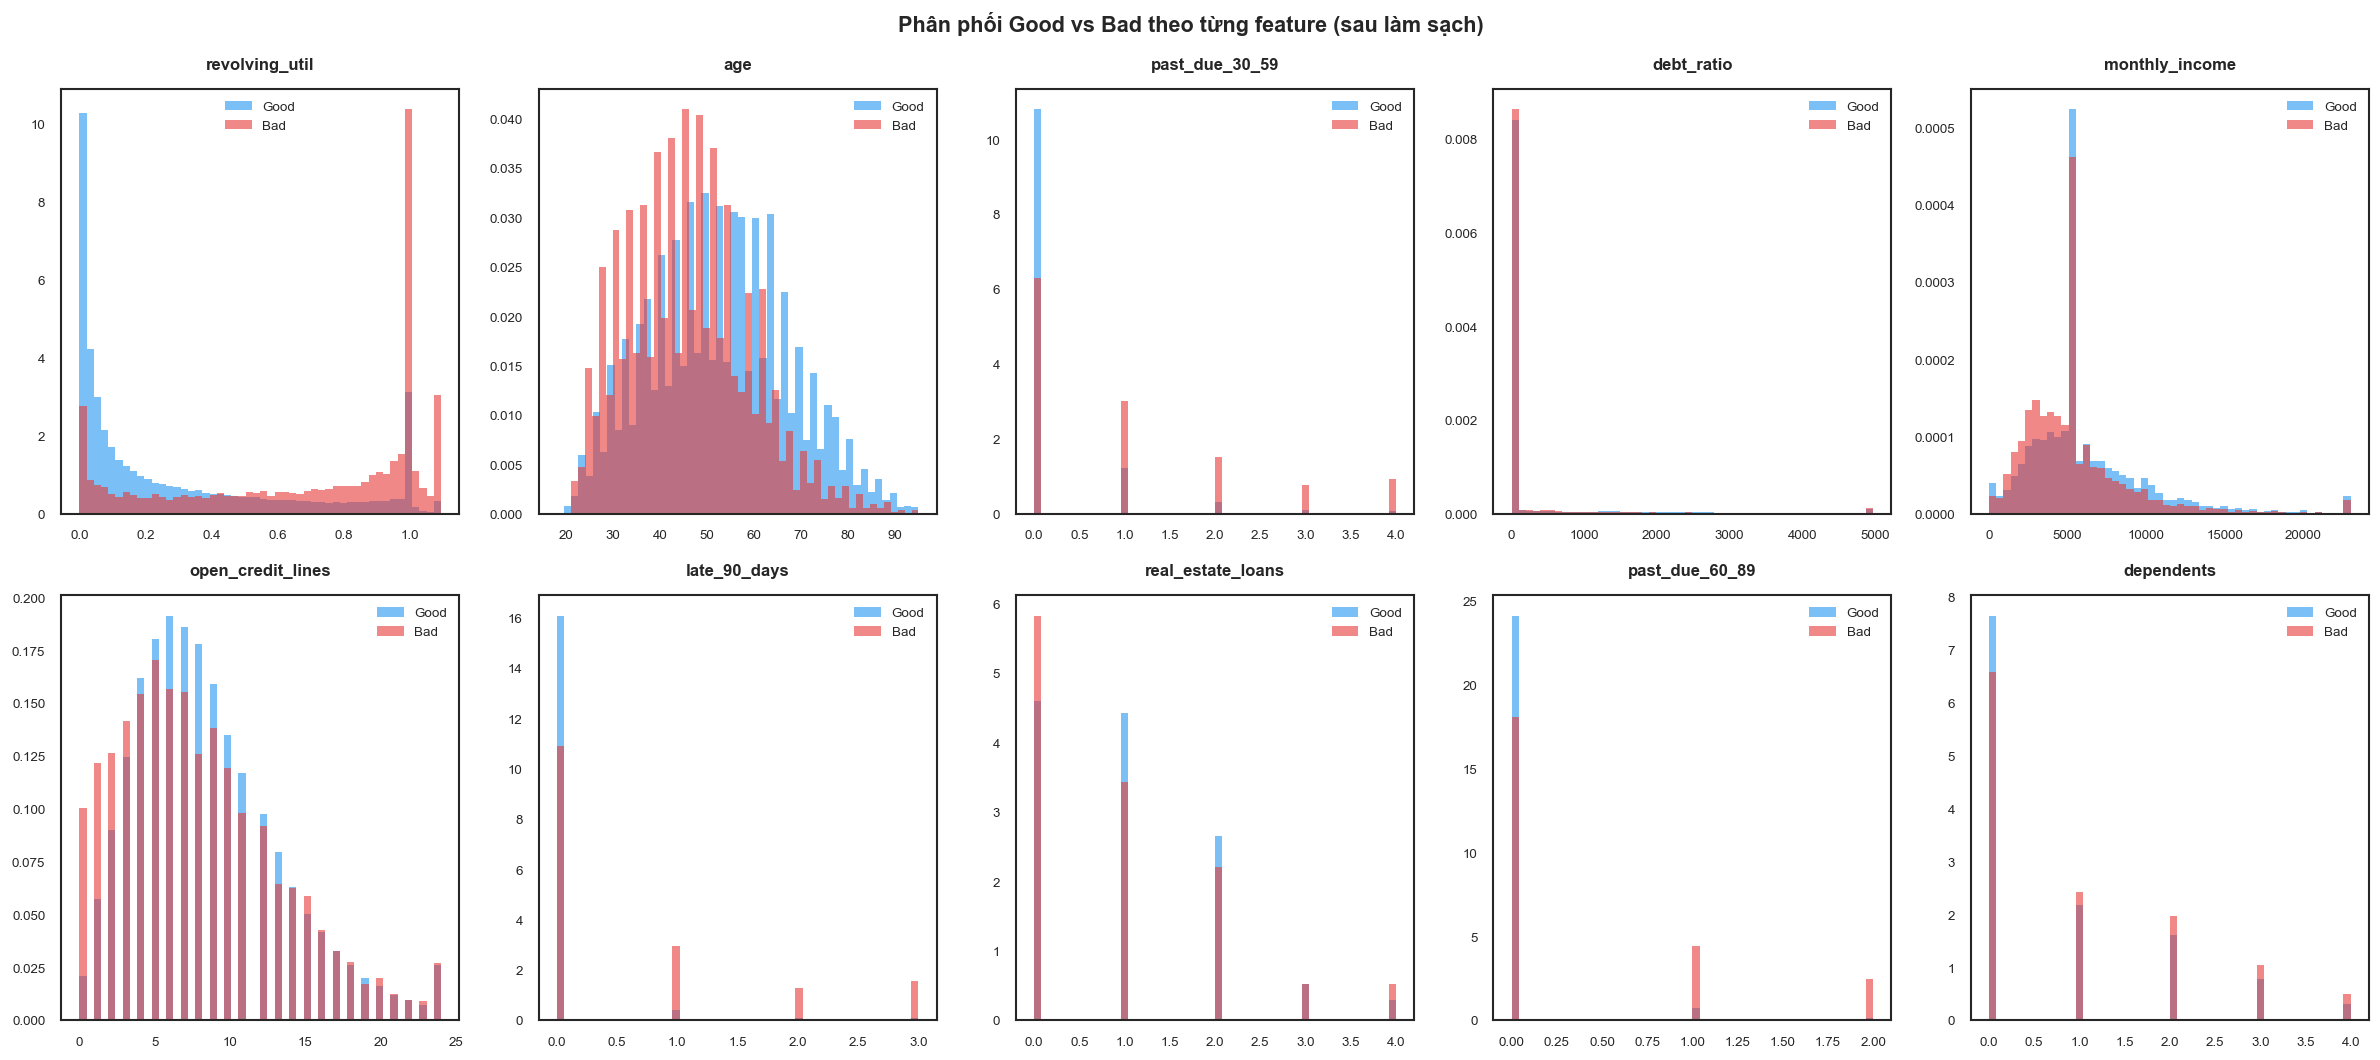

Nhận xét: Các cột 'past_due_*' và 'late_90_days' có sự tách biệt rõ nhất
→ Kỳ vọng IV cao ở bước WOE tiếp theo


In [37]:
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    good_vals = df.loc[df["target"] == 0, col]
    bad_vals  = df.loc[df["target"] == 1, col]

    axes[i].hist(good_vals, bins=50, alpha=0.6, color=PALETTE["good"],
                 label="Good", density=True, edgecolor="none")
    axes[i].hist(bad_vals,  bins=50, alpha=0.6, color=PALETTE["bad"],
                 label="Bad",  density=True, edgecolor="none")
    axes[i].set_title(col, fontsize=10)
    axes[i].legend(fontsize=8, frameon=False)
    axes[i].tick_params(labelsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Phân phối Good vs Bad theo từng feature (sau làm sạch)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("05_feature_distribution_by_target.png", bbox_inches="tight")
plt.show()

print("Nhận xét: Các cột 'past_due_*' và 'late_90_days' có sự tách biệt rõ nhất")
print("→ Kỳ vọng IV cao ở bước WOE tiếp theo")

### Correlation Matrix — Kiểm tra multicollinearity

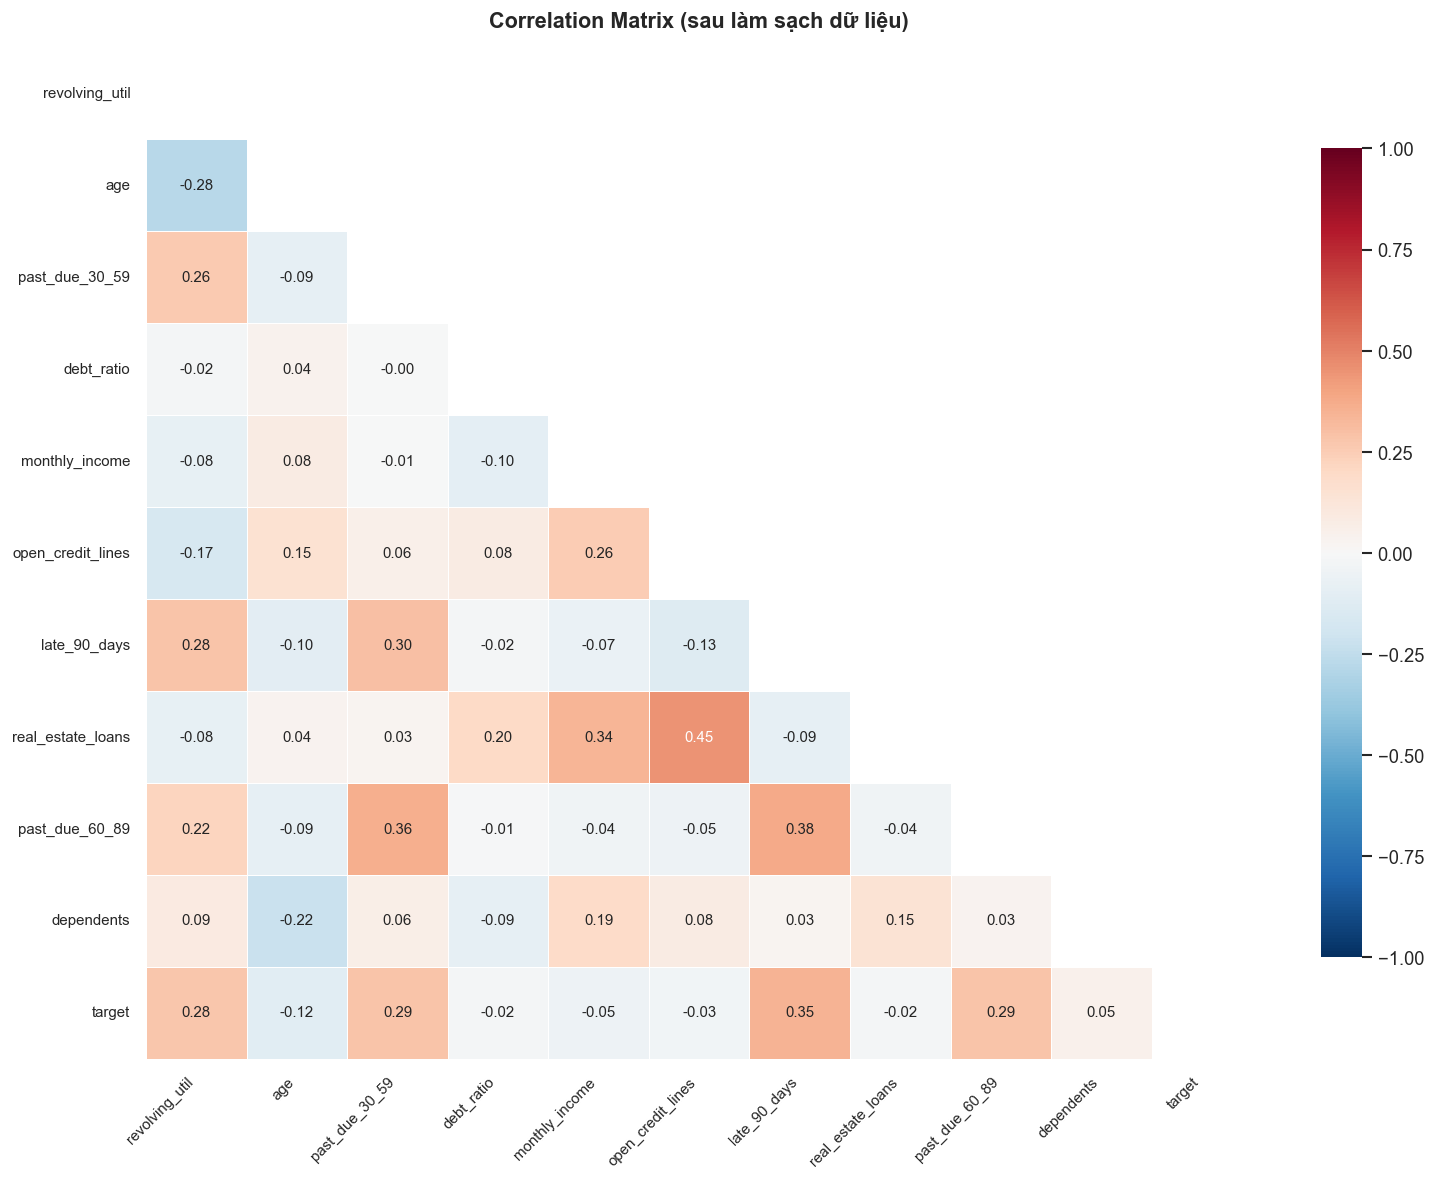


Cặp feature có |correlation| > 0.7 (nguy cơ multicollinearity):
  ✓ Không phát hiện multicollinearity nghiêm trọng


In [39]:
corr = df[NUM_COLS + ["target"]].corr()

# Mask tam giác trên để dễ đọc
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 9},
    ax=ax,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Correlation Matrix (sau làm sạch dữ liệu)", fontsize=13, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig("06_correlation_matrix.png", bbox_inches="tight")
plt.show()

# Phát hiện cặp multicollinear (|corr| > 0.7, loại trừ cặp với target)
print("\nCặp feature có |correlation| > 0.7 (nguy cơ multicollinearity):")
threshold = 0.7
found = False
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        c1, c2 = corr.columns[i], corr.columns[j]
        if c1 == "target" or c2 == "target":
            continue
        val = corr.iloc[i, j]
        if abs(val) > threshold:
            print(f"  {c1:35s} ↔ {c2:35s}  r = {val:.3f}")
            found = True
if not found:
    print("  ✓ Không phát hiện multicollinearity nghiêm trọng")

### Saving cleaning data & Summarise

In [42]:
# ── Kiểm tra lần cuối trước khi lưu ─────────────────────────────────────────
print("=== KIỂM TRA CHẤT LƯỢNG DỮ LIỆU SAU XỬ LÝ ===")
print(f"  Shape          : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"  Missing values : {df.isnull().sum().sum()}")
print(f"  Duplicate rows : {df.duplicated().sum():,}")
print(f"  Target (0/1)   : {(df['target']==0).sum():,} / {(df['target']==1).sum():,}")
print(f"  Bad rate       : {df['target'].mean()*100:.2f}%")
print()
print("── Thống kê mô tả sau làm sạch ──")
print(df.describe(percentiles=[0.01, 0.5, 0.99]).T.round(3).to_string())


=== KIỂM TRA CHẤT LƯỢNG DỮ LIỆU SAU XỬ LÝ ===
  Shape          : 150,000 rows × 12 columns
  Missing values : 0
  Duplicate rows : 777
  Target (0/1)   : 139,974 / 10,026
  Bad rate       : 6.68%

── Thống kê mô tả sau làm sạch ──
                              count       mean        std     min      1%        50%         99%         max
target                 150,000.0000     0.0670     0.2500  0.0000  0.0000     0.0000      1.0000      1.0000
revolving_util         150,000.0000     0.3200     0.3520  0.0000  0.0000     0.1540      1.0930      1.0930
age                    150,000.0000    52.2940    14.7670 18.0000 24.0000    52.0000     87.0000     95.0000
past_due_30_59         150,000.0000     0.2460     0.6670  0.0000  0.0000     0.0000      4.0000      4.0000
debt_ratio             150,000.0000   316.5490   906.9620  0.0000  0.0000     0.3670  4,979.0000  4,979.0400
monthly_income         150,000.0000 6,142.4450 3,835.6790  0.0000  0.0000 5,400.0000 23,000.0000 23,000.0000
open_c

In [43]:
OUTPUT_PATH = "cs_training_cleaned.csv"
df.to_csv(OUTPUT_PATH, index=False)
print(f"✓ Đã lưu: {OUTPUT_PATH}")
print()
print("=== TÓM TẮT BƯỚC 1 ===")
print(f"  Raw data  : {df_raw.shape[0]:,} rows, {df_raw.isnull().sum().sum():,} missing values")
print(f"  Clean data: {df.shape[0]:,} rows, {df.isnull().sum().sum()} missing values")
print(f"  Thêm mới  : cột 'monthly_income_missing' (flag MAR)")
print(f"  Winsorized: {len(UPPER_ONLY) + 2} cột")
print()
print("─── Bước tiếp theo: Bước 2 — WOE / IV Encoding ───")

✓ Đã lưu: cs_training_cleaned.csv

=== TÓM TẮT BƯỚC 1 ===
  Raw data  : 150,000 rows, 33,655 missing values
  Clean data: 150,000 rows, 0 missing values
  Thêm mới  : cột 'monthly_income_missing' (flag MAR)
  Winsorized: 10 cột

─── Bước tiếp theo: Bước 2 — WOE / IV Encoding ───
